# 03 — Contrast, post-processing gain and separation

Three coronagraph numbers decide whether a planet is detectable at all: the **raw dark-hole
contrast** (how much starlight leaks through), the **post-processing gain** (how much of that
leak a reference subtraction removes), and the **separation** relative to the mask's inner
working angle.

In this notebook:
1. the raw contrast sweep and the plateau,
2. the post-processing gain,
3. the separation and the mask's off-axis throughput,
4. time to S/N 5 versus planet contrast: the floor,
5. reference-star subtraction (RDI).

In [1]:
import warnings
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
import esc_etc
from esc_etc import Simulation, use_lazuli_style

use_lazuli_style()
warnings.filterwarnings("ignore", module="synphot")

sim = Simulation.from_default(filter="R3", hoststarmag=4.83, hoststar_band="johnson_v",
                              planetdeltamag=20, contrast=1e-8, ppgain=10, separation=0.4)

def frame_for(sim, max_frame=1000 * u.s):
    """Frame time to use: max_frame, or half the saturation time if that is shorter."""
    return min(u.Quantity(max_frame, u.s), 0.5 * sim.saturation_time())


def hours_to_snr(sim, snr=5, max_frame=1000 * u.s):
    """Integration time (hours) to reach snr with the current configuration; NaN above the speckle plateau."""
    return sim.get_int_time_for_snr(snr, frame_for(sim, max_frame))["int_time_continuous"][0].to_value(u.hr)

***
## 1. Raw contrast

`plot_snr_vs_time(sweep={...})` draws one curve per value of any `update()` key.

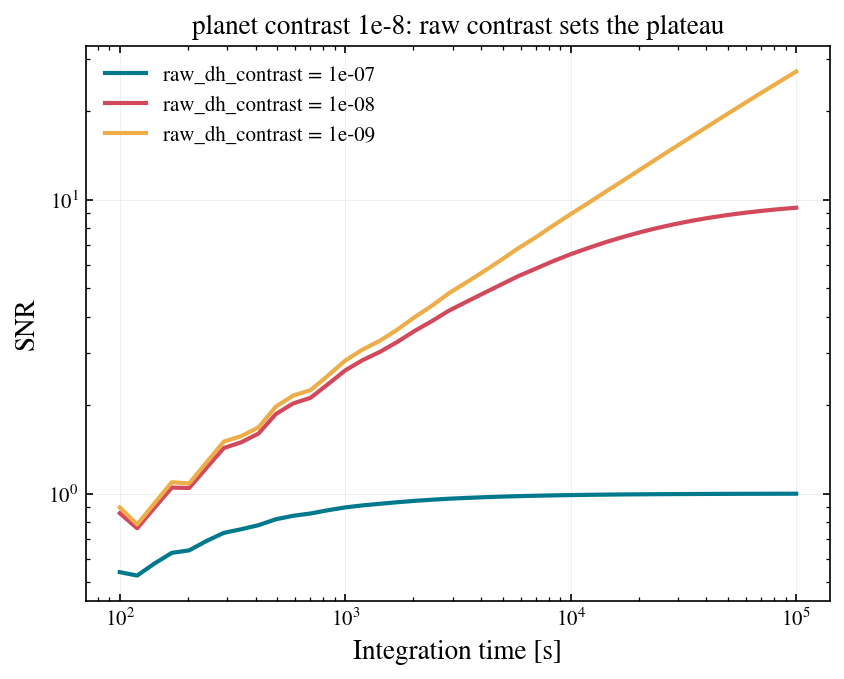

raw contrast 1e-07: S/N in 1 h = 0.97, plateau = 1
raw contrast 1e-08: S/N in 1 h = 4.59, plateau = 10
raw contrast 1e-09: S/N in 1 h = 5.37, plateau = 100


In [2]:
fig, ax = sim.plot_snr_vs_time(sweep={"coronagraph__raw_dh_contrast": [1e-7, 1e-8, 1e-9]})
ax.set_title("planet contrast 1e-8: raw contrast sets the plateau")
plt.show()
for c in (1e-7, 1e-8, 1e-9):
    sim.update(coronagraph__raw_dh_contrast=c)
    print(f"raw contrast {c:.0e}: S/N in 1 h = {sim.get_snr(3600, 100)['snr']:.2f}, plateau = {10 * 1e-8 / c:.0f}")
sim.reset()

At raw contrast $10^{-7}$ the plateau is $10 \times 10^{-8}/10^{-7} = 1$: the planet is ten times
fainter than the speckles and post-processing by 10 only brings them level. Nothing is detected,
ever.

***
## 2. Post-processing gain

> ✏️ **Before you run the next cell:** going from ppgain 10 to 100, does the one-hour S/N on this planet go up by 10 %, by a factor 2, or by a factor 10? Write your guess down (or put it in the room poll), then run.

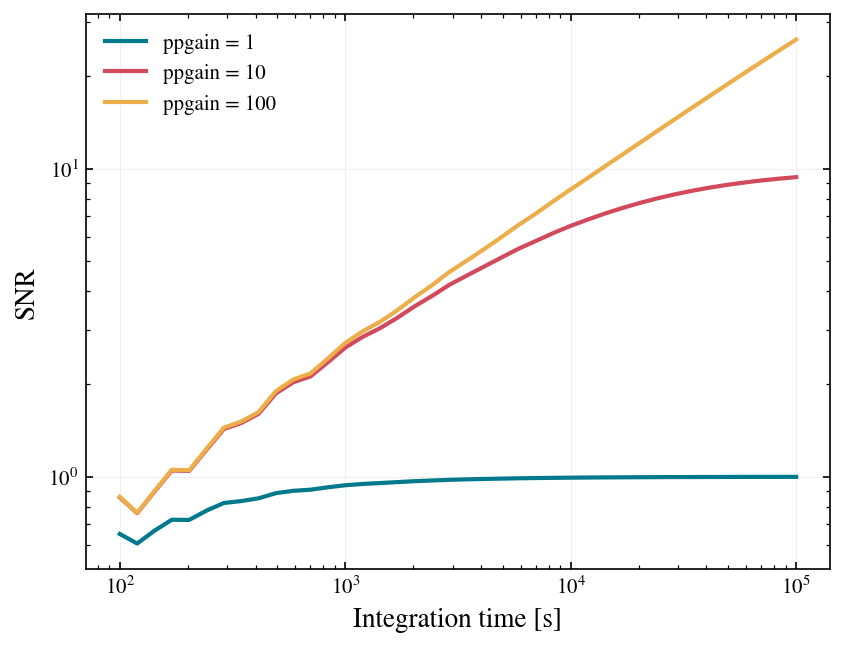

ppgain   1: S/N in 1 h =  0.98, in 10 h =  1.00, plateau 1
ppgain  10: S/N in 1 h =  4.59, in 10 h =  8.53, plateau 10


ppgain 100: S/N in 1 h =  5.15, in 10 h = 16.11, plateau 100


In [3]:
fig, ax = sim.plot_snr_vs_time(sweep={"coronagraph__ppgain": [1, 10, 100]})
plt.show()
for g in (1, 10, 100):
    sim.update(coronagraph__ppgain=g)
    print(f"ppgain {g:3d}: S/N in 1 h = {sim.get_snr(3600, 100)['snr']:5.2f}, in 10 h = {sim.get_snr(10 * u.hr, 100)['snr']:5.2f}, plateau {g * 1e-8 / 1e-8:.0f}")
sim.reset()

The gain lifts the plateau but hardly changes the first hour: there the photon noise of the speckles
(not their systematic residual) dominates, and `ppgain` does nothing about photon noise.

***
## 3. Separation and the mask throughput

The vortex mask transmits the planet with a throughput that rises from zero on axis to about 65 %
beyond 10 $\lambda/D$. The configuration tabulates it out to 20 $\lambda/D$; the ETC refuses
separations beyond that. A common definition of the inner working angle (IWA) is 50 % of the peak
throughput.

lambda/D = 45.3 mas at 659 nm; table edge 0.906" (20 lambda/D)
peak throughput 0.65; IWA (50 % of peak) = 0.165" = 3.6 lambda/D
  0.1": throughput 0.166
  0.2": throughput 0.412
  0.4": throughput 0.573
  0.8": throughput 0.647


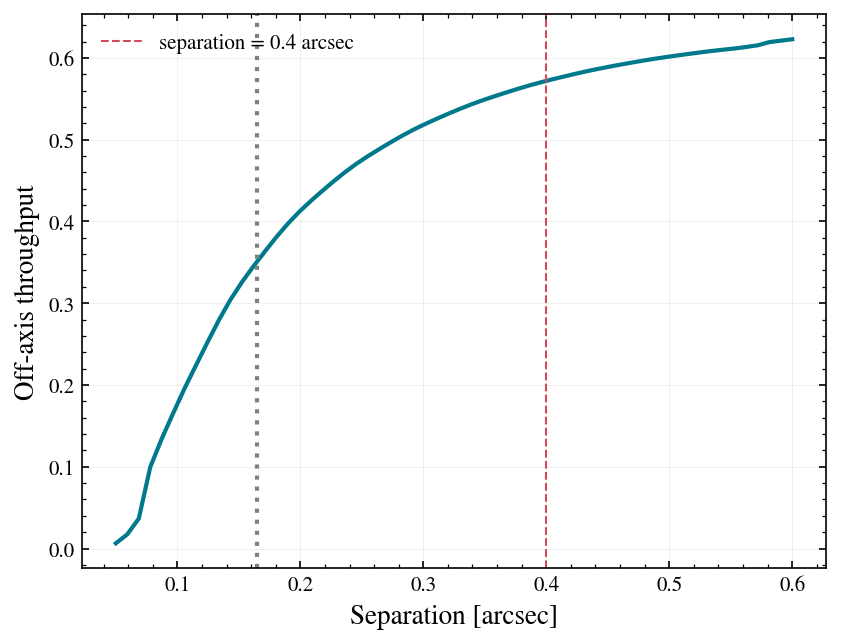

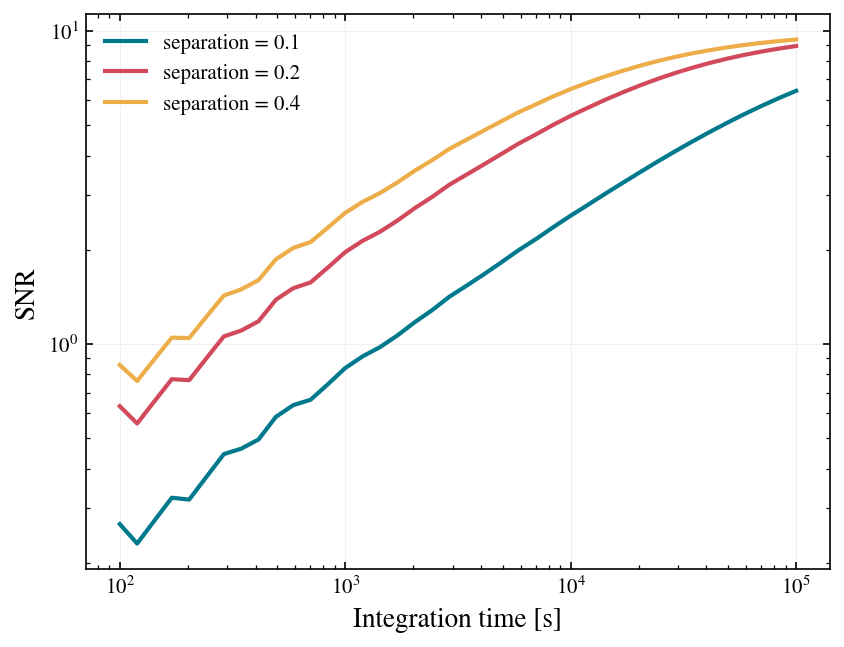

In [4]:
cg = sim.coronagraph
lamD = (cg.primary_filter / cg.diameter_primary).to_value(u.arcsec, equivalencies=u.dimensionless_angles())
seps = cg._lamD * lamD
thr = cg._throughput
IWA = seps[np.argmax(thr >= 0.5 * thr.max())]
print(f"lambda/D = {lamD * 1e3:.1f} mas at {cg.primary_filter.to(u.nm):.0f}; table edge {seps.max():.3f}\" (20 lambda/D)")
print(f"peak throughput {thr.max():.2f}; IWA (50 % of peak) = {IWA:.3f}\" = {IWA / lamD:.1f} lambda/D")
for sep in (0.1, 0.2, 0.4, 0.8):
    print(f"  {sep:.1f}\": throughput {cg.off_axis_throughput(sep):.3f}")
fig, ax = sim.plot_offaxis_throughput()
ax.axvline(IWA, color="0.5", ls=":")
plt.show()
fig, ax = sim.plot_snr_vs_time(sweep={"coronagraph__separation": [0.1, 0.2, 0.4]})
plt.show()

The throughput scales planet *and* speckle rates alike, so the plateau does not move with
separation; only the time to get there does. (The raw contrast is a single number across the dark
hole in this model: in reality it degrades towards the IWA.)

***
## 4. Time to S/N 5 versus planet contrast

The floor in contrast: S/N 5 needs a plateau above 5, i.e. $C_\mathrm{planet} > 5\,C_\mathrm{raw}/\mathrm{ppgain}$.
`hours_to_snr` (defined in the setup cell) wraps `get_int_time_for_snr` with a frame time capped
at half the saturation time, and returns NaN above the plateau.

ppgain  10: floor at C = 5 x 1e-8 / 10 = 5.0e-09; a 1e-8 planet takes 0.40 h


ppgain  30: floor at C = 5 x 1e-8 / 30 = 1.7e-09; a 1e-8 planet takes 0.31 h


ppgain 100: floor at C = 5 x 1e-8 / 100 = 5.0e-10; a 1e-8 planet takes 0.30 h


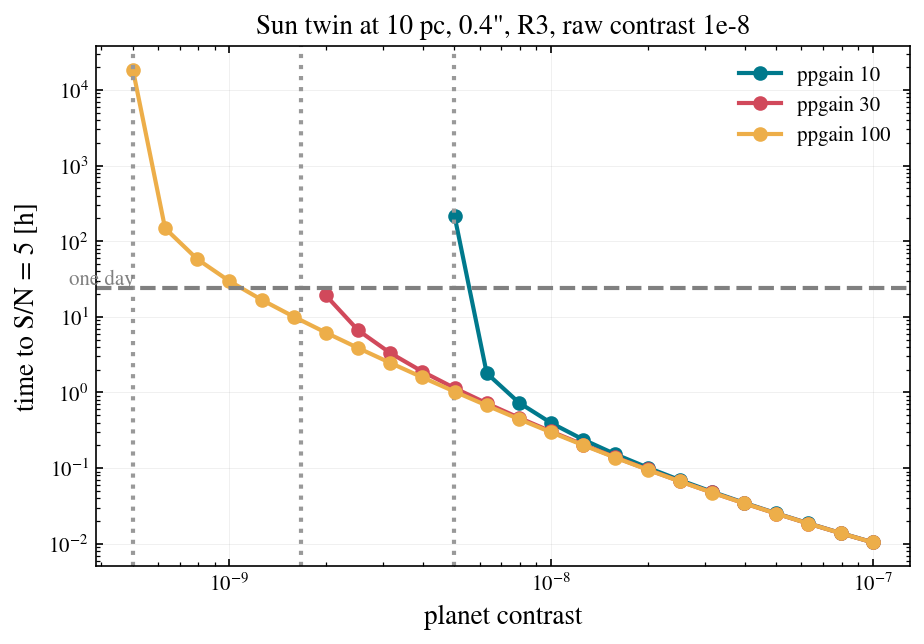

In [5]:
contrasts = np.logspace(-9.5, -7, 26)
fig, ax = plt.subplots(figsize=(7, 4.5))
for g in (10, 30, 100):
    hours = []
    for c in contrasts:
        sim.update(scene__planet__deltamag=-2.5 * np.log10(c), coronagraph__ppgain=g)
        hours.append(hours_to_snr(sim))
    sim.reset()
    ax.loglog(contrasts, hours, "o-", label=f"ppgain {g}")
    ax.axvline(5e-8 / g, color="0.6", ls=":")
    print(f"ppgain {g:3d}: floor at C = 5 x 1e-8 / {g} = {5e-8 / g:.1e}; a 1e-8 planet takes {hours[np.argmin(np.abs(contrasts - 1e-8))]:.2f} h")
ax.axhline(24, color="0.5", ls="--"); ax.text(contrasts[0], 27, "one day", color="0.5")
ax.set(xlabel="planet contrast", ylabel="time to S/N = 5 [h]", title="Sun twin at 10 pc, 0.4\", R3, raw contrast 1e-8")
ax.legend()
plt.show()

***
## 5. Reference-star subtraction

`coronagraph__subtraction="rdi"` models a reference star observed for `ref_time_ratio` times the
science time at `ref_brightness_ratio` times the brightness: its noise is added, and the charged
time grows.

In [6]:
sim.update(coronagraph__subtraction="rdi", coronagraph__ref_time_ratio=1.0, coronagraph__ref_brightness_ratio=1.0)
r = sim.get_snr(3600, 100)
print(f"RDI: S/N {r['snr']:.2f} in {r['science_time']:.0f} of science time, {r['charged_time']:.0f} charged, reference noise {r['reference_noise_e']:.1f} e-")
sim.update(coronagraph__ref_brightness_ratio=4.0)
print(f"with a 4x brighter reference: S/N {sim.get_snr(3600, 100)['snr']:.2f}")
sim.reset()
print(f"no subtraction: S/N {sim.get_snr(3600, 100)['snr']:.2f}")

RDI: S/N 3.50 in 3600 s of science time, 7200 s charged, reference noise 55.8 e-
with a 4x brighter reference: S/N 4.46
no subtraction: S/N 4.59


> 🤖 **Ask Jupyter AI:** *Starting from the S/N formula in notebook 01 (or esc_etc/noise.py), derive the plateau S/N = ppgain x C_planet / C_raw, and then the contrast floor for S/N = 5. Check it against the vertical lines in the plot above.*
>
> Then ask what happens to the floor if the raw contrast were a function of separation, say 1e-8 at 10 lambda/D rising to 1e-7 at the IWA.

***
## Summary

```python
sim.plot_snr_vs_time(sweep={"coronagraph__raw_dh_contrast": [1e-7, 1e-8, 1e-9]})   # any update() key
sim.coronagraph.off_axis_throughput(0.2); sim.plot_offaxis_throughput()
plateau = ppgain * C_planet / C_raw;  floor: C_planet > 5 * C_raw / ppgain
sim.update(coronagraph__subtraction="rdi", coronagraph__ref_time_ratio=1, coronagraph__ref_brightness_ratio=1)
```

Next: [04 — frame time, read noise and saturation](04_frame_time_saturation.ipynb).